Dataset overview

**Goal:** Understand structure. You can tell your supervisor: the file organizes **multiple sessions** (columns in `data['data']`), each with continuous EEG and metadata.


In [1]:
from scipy.io import loadmat

data = loadmat("../data/A01T.mat")

print("Keys:", data.keys())
print("Shape of data:", data["data"].shape)

Keys: dict_keys(['__header__', '__version__', '__globals__', 'data'])
Shape of data: (1, 9)


Explore one session

**Fields:**
- **X** — continuous EEG (time × channels)
- **y** — trial labels
- **trial** — sample indices where each trial starts
- **fs** — sampling rate (Hz)
- **classes** — text names for class ids


In [2]:
session = data["data"][0, 0]

print("Fields:", session.dtype.names)

Fields: ('X', 'trial', 'y', 'fs', 'classes', 'artifacts', 'gender', 'age')


**Explain:** EEG matrix **X** is **time samples × channels** (here 25 EEG channels). **fs = 250 Hz** means 250 samples per second. Labels **y** and **trial** may be empty for some sessions (e.g. practice runs).


In [3]:
X = session["X"][0, 0]
y = session["y"][0, 0]
trial = session["trial"][0, 0]
fs = session["fs"][0, 0]
classes = session["classes"][0, 0]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("trial shape:", trial.shape)
print("Sampling rate:", fs)
print("Classes:", classes)

X shape: (29683, 25)
y shape: (0, 1)
trial shape: (0, 1)
Sampling rate: [[250]]
Classes: [[array(['left hand'], dtype='<U9') array(['right hand'], dtype='<U10')
  array(['feet'], dtype='<U4') array(['tongue'], dtype='<U6')]]


EEG is **noisy**; amplitude fluctuates with brain activity, muscle, line noise, etc.


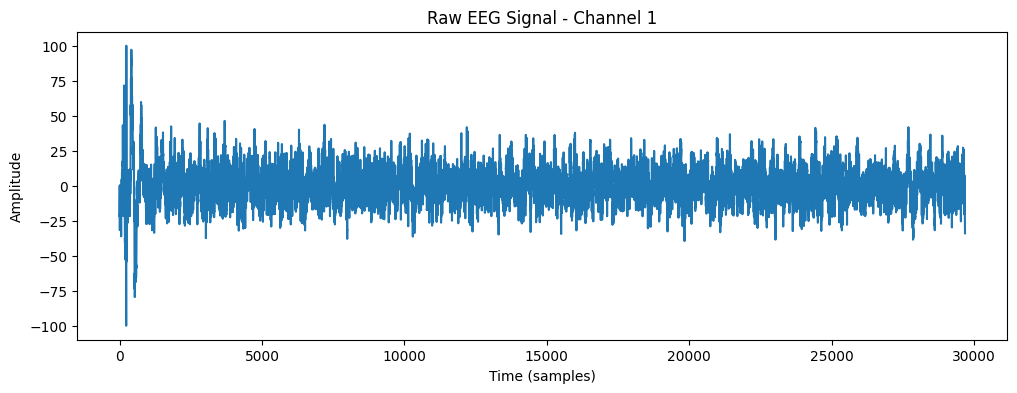

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(X[:, 0])
plt.title("Raw EEG Signal - Channel 1")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude")
plt.show()

List sessions and find one where **y** and **trial** are non-empty so you can segment trials.


In [5]:
for i in range(data["data"].shape[1]):
    session = data["data"][0, i]

    X = session["X"][0, 0]
    y = session["y"][0, 0]
    trial = session["trial"][0, 0]

    print(f"Session {i}")
    print("  y shape:", y.shape)
    print("  trial shape:", trial.shape)
    print("-" * 30)

Session 0
  y shape: (0, 1)
  trial shape: (0, 1)
------------------------------
Session 1
  y shape: (0, 1)
  trial shape: (0, 1)
------------------------------
Session 2
  y shape: (0, 1)
  trial shape: (0, 1)
------------------------------
Session 3
  y shape: (48, 1)
  trial shape: (48, 1)
------------------------------
Session 4
  y shape: (48, 1)
  trial shape: (48, 1)
------------------------------
Session 5
  y shape: (48, 1)
  trial shape: (48, 1)
------------------------------
Session 6
  y shape: (48, 1)
  trial shape: (48, 1)
------------------------------
Session 7
  y shape: (48, 1)
  trial shape: (48, 1)
------------------------------
Session 8
  y shape: (48, 1)
  trial shape: (48, 1)
------------------------------


Extract one trial

Use a session index that has labels (from Step 5). The template used **column 3**; if your printout shows another column with non-empty `y`, change the index to match.

Below we also set `valid_session_idx` to the **first** session with at least one label so the same notebook works across files without manual guessing.


In [6]:
valid_session_idx = None
for i in range(data["data"].shape[1]):
    s = data["data"][0, i]
    y_s = s["y"][0, 0]
    if y_s.size > 0:
        valid_session_idx = i
        break

if valid_session_idx is None:
    raise ValueError("No session with labels found — check .mat file.")

# Original template: session = data['data'][0, 3]
session = data["data"][0, valid_session_idx]

X = session["X"][0, 0]
y = session["y"][0, 0]
trial = session["trial"][0, 0]

fs = int(session["fs"][0, 0].squeeze())
window = 4 * fs

start = int(trial[0][0])
end = start + window

trial_signal = X[start:end, :]
label = int(y[0][0])

print("Using session index:", valid_session_idx)
print("Trial shape:", trial_signal.shape)
print("Label:", label)

Using session index: 3
Trial shape: (1000, 25)
Label: 4


Visualize one trial


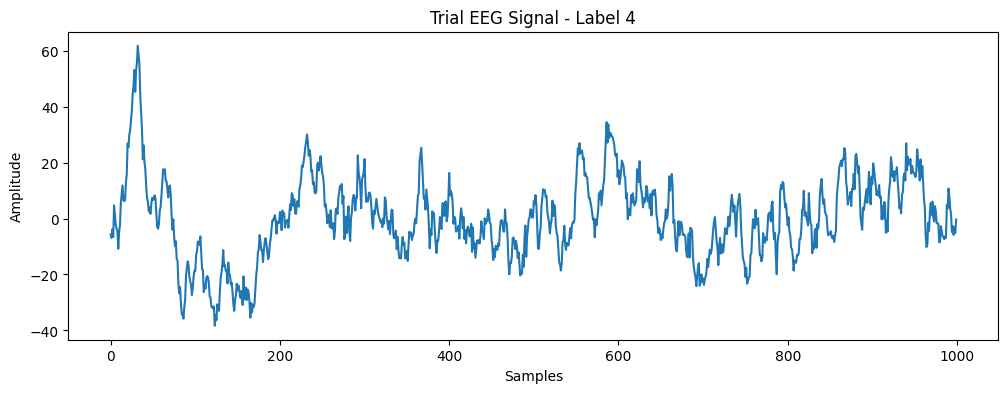

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(trial_signal[:, 0])
plt.title(f"Trial EEG Signal - Label {label}")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

The full 2a task has four classes (**1 = left**, **2 = right**, **3 = feet**, **4 = tongue**); the `classes` field in the file lists all four. **This research uses only left vs right hand**: the training code in `src/load_data.py` keeps trials with labels 1 and 2 only and maps them to **0 = left**, **1 = right**. Raw left vs right traces can still look similar; filtering + models (EEGNet) help.


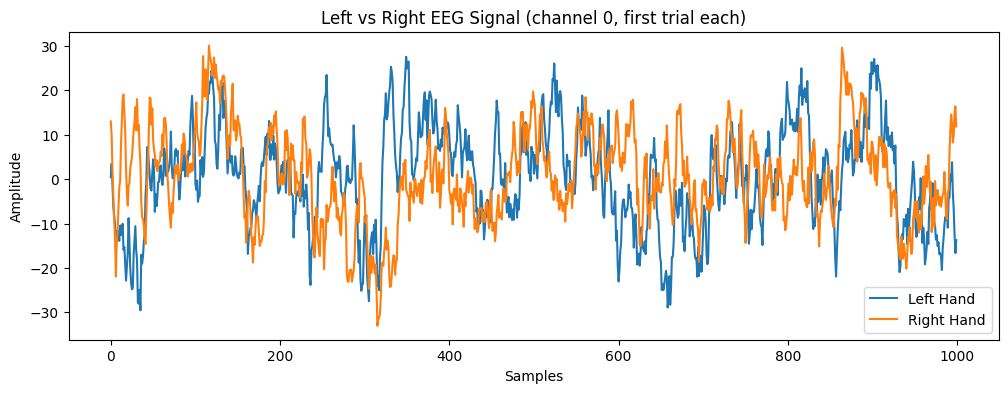

In [8]:
session = data["data"][0, valid_session_idx]
X = session["X"][0, 0]
y = session["y"][0, 0]
trial = session["trial"][0, 0]
fs = int(session["fs"][0, 0].squeeze())
window = 4 * fs

left_trials = []
right_trials = []

for i in range(len(trial)):
    start = int(trial[i][0])
    end = start + window

    if end <= X.shape[0]:
        segment = X[start:end, :]
        label = int(y[i][0])

        if label == 1:
            left_trials.append(segment)
        elif label == 2:
            right_trials.append(segment)

if not left_trials or not right_trials:
    raise ValueError(
        "Need at least one left (1) and one right (2) trial in this session. "
        f"Got left={len(left_trials)}, right={len(right_trials)}"
    )

plt.figure(figsize=(12, 4))
plt.plot(left_trials[0][:, 0], label="Left Hand")
plt.plot(right_trials[0][:, 0], label="Right Hand")
plt.legend()
plt.title("Left vs Right EEG Signal (channel 0, first trial each)")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

In [9]:
from pathlib import Path

DATA_DIR = Path("../data").resolve()
mat_files = sorted(DATA_DIR.glob("*.mat"))
print(f"Found {len(mat_files)} file(s) in:\n  {DATA_DIR}\n")
for p in mat_files:
    print(" ", p.name)
if not mat_files:
    print("Tip: place A01T.mat … A09E.mat (or any Graz 2a .mat) inside the data/ folder next to this notebook.")

Found 9 file(s) in:
  D:\AI Degree\Level 04 Sem 02\Research project in AI\Research project files\data

  A01T.mat
  A02T.mat
  A03T.mat
  A04T.mat
  A05T.mat
  A06T.mat
  A07T.mat
  A08T.mat
  A09T.mat


In [10]:
def summarize_bcic_iv_2a_mat(path: Path) -> None:
    """One summary block per file — same schema as A01T (Graz 2a)."""
    d = loadmat(path)
    if "data" not in d:
        print(f"\n=== {path.name} ===\n  no 'data' key — not standard Graz 2a .mat layout.")
        return
    block = d["data"]
    n_sessions = block.shape[1]
    print(f"\n=== {path.name} ===")
    print(f"  data['data'] shape: {block.shape}  → {n_sessions} session column(s)")
    total_labeled_trials = 0
    chans = fs_ref = None
    for i in range(n_sessions):
        sess = block[0, i]
        X = sess["X"][0, 0]
        y = sess["y"][0, 0]
        trial = sess["trial"][0, 0]
        fs = int(sess["fs"][0, 0].squeeze())
        if chans is None:
            chans = X.shape[1]
        fs_ref = fs
        if y.size and trial.size:
            n_tr = trial.shape[0]
            total_labeled_trials += n_tr
            print(f"  session {i}: X {X.shape}, labeled trials = {n_tr}, fs = {fs} Hz")
    print(f"  → channels = {chans}, fs = {fs_ref} Hz, total labeled trials (file) = {total_labeled_trials}")


for mat_path in mat_files:
    summarize_bcic_iv_2a_mat(mat_path)


=== A01T.mat ===
  data['data'] shape: (1, 9)  → 9 session column(s)
  session 3: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 4: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 5: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 6: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 7: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 8: X (96735, 25), labeled trials = 48, fs = 250 Hz
  → channels = 25, fs = 250 Hz, total labeled trials (file) = 288

=== A02T.mat ===
  data['data'] shape: (1, 9)  → 9 session column(s)
  session 3: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 4: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 5: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 6: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 7: X (96735, 25), labeled trials = 48, fs = 250 Hz
  session 8: X (96735, 25), labeled trials = 48, fs = 250 Hz
  → channels = 25, fs = 250 Hz, total labeled trials (file) = 

### Quick visual comparison (channel 0, first ~5 s of session 0)

Same y-axis scale is not enforced across subjects — this is only to **see** that every file has comparable continuous EEG before trial cutting.

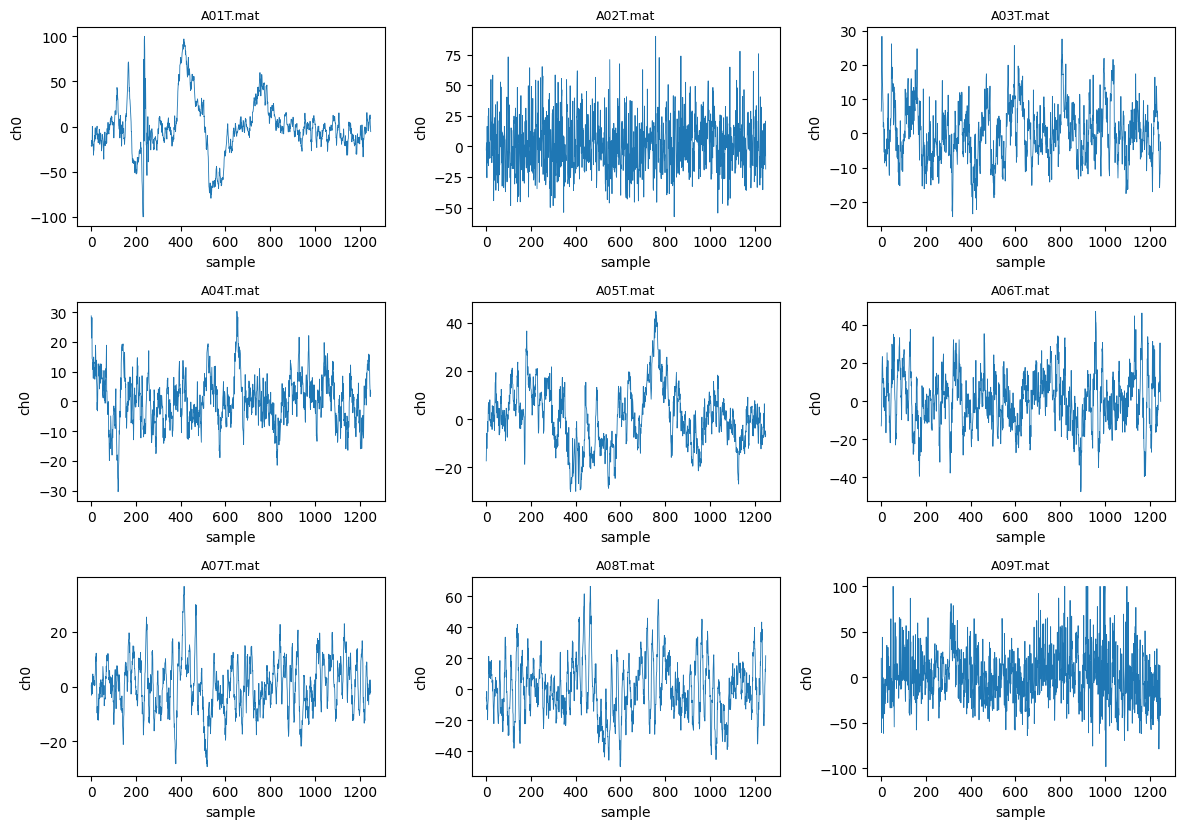

In [13]:
import math

if not mat_files:
    print("No .mat files to plot.")
else:
    n_files = len(mat_files)
    ncols = min(3, n_files)
    nrows = math.ceil(n_files / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False)
    for idx, path in enumerate(mat_files):
        r, c = divmod(idx, ncols)
        ax = axes[r][c]
        d = loadmat(path)
        X0 = d["data"][0, 0]["X"][0, 0]
        fs0 = int(d["data"][0, 0]["fs"][0, 0].squeeze())
        n_plot = min(5 * fs0, X0.shape[0])
        ax.plot(X0[:n_plot, 0], lw=0.6)
        ax.set_title(path.name, fontsize=9)
        ax.set_xlabel("sample")
        ax.set_ylabel("ch0")
    for j in range(idx + 1, nrows * ncols):
        r, c = divmod(j, ncols)
        axes[r][c].set_visible(False)
    plt.tight_layout()
    plt.show()

### Same subject: training (`T`) vs evaluation (`E`)

If you have both `AxxT.mat` and `AxxE.mat`, this lists pairs so you can compare **T** vs **E** for cross-session / domain-shift experiments later.

In [12]:
import re

pairs: dict[str, dict[str, Path]] = {}
for p in mat_files:
    m = re.match(r"A(\d+)([TE])\.mat", p.name, re.I)
    if m:
        subj, kind = m.group(1), m.group(2).upper()
        pairs.setdefault(subj, {})[kind] = p

for subj in sorted(pairs.keys(), key=int):
    kinds = pairs[subj]
    if "T" in kinds and "E" in kinds:
        print(f"Subject {subj}:  {kinds['T'].name}  +  {kinds['E'].name}")
    else:
        missing = "T" if "T" not in kinds else "E"
        print(f"Subject {subj}: only {list(kinds.values())[0].name} (missing {missing})")

Subject 01: only A01T.mat (missing E)
Subject 02: only A02T.mat (missing E)
Subject 03: only A03T.mat (missing E)
Subject 04: only A04T.mat (missing E)
Subject 05: only A05T.mat (missing E)
Subject 06: only A06T.mat (missing E)
Subject 07: only A07T.mat (missing E)
Subject 08: only A08T.mat (missing E)
Subject 09: only A09T.mat (missing E)
